# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import LEVIRCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/levir_cd/train/",
}
dataset = LEVIRCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 445


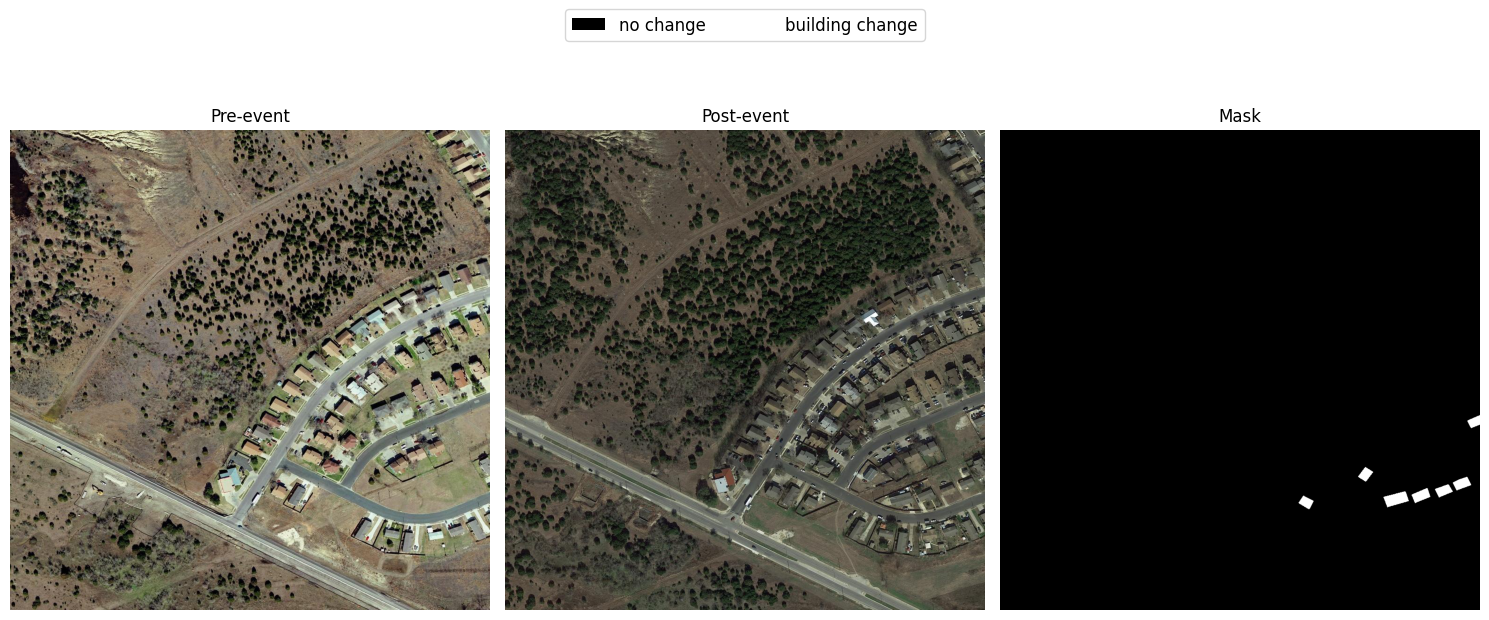

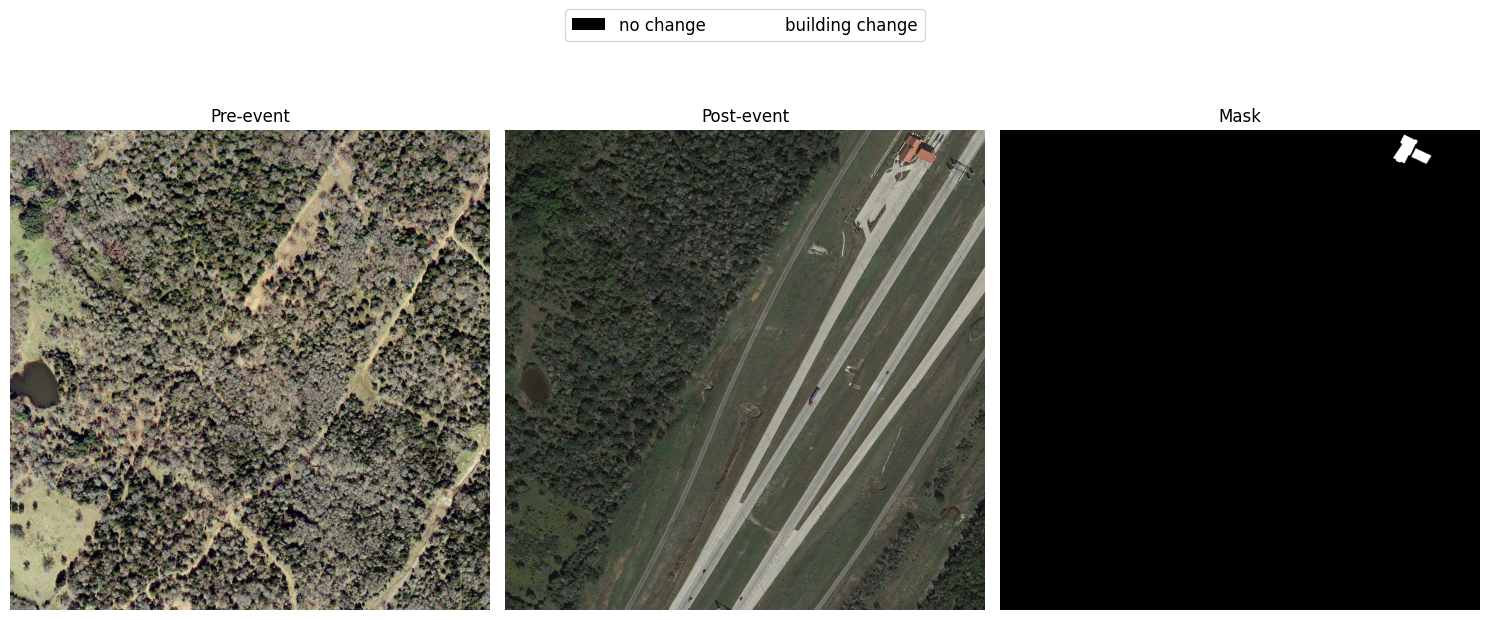

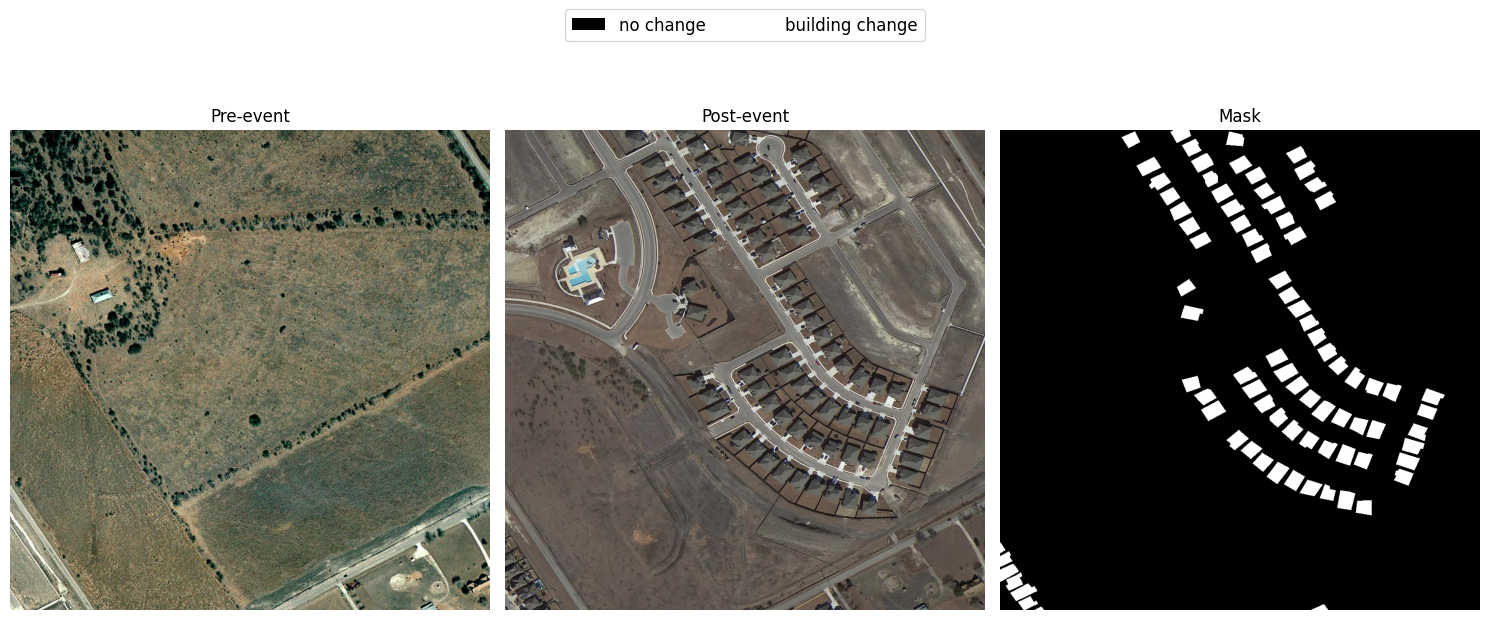

In [6]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [7]:
dataset.data_distribution_table()

,Number of pixels
no change,445203979.0
building change,21412341.0


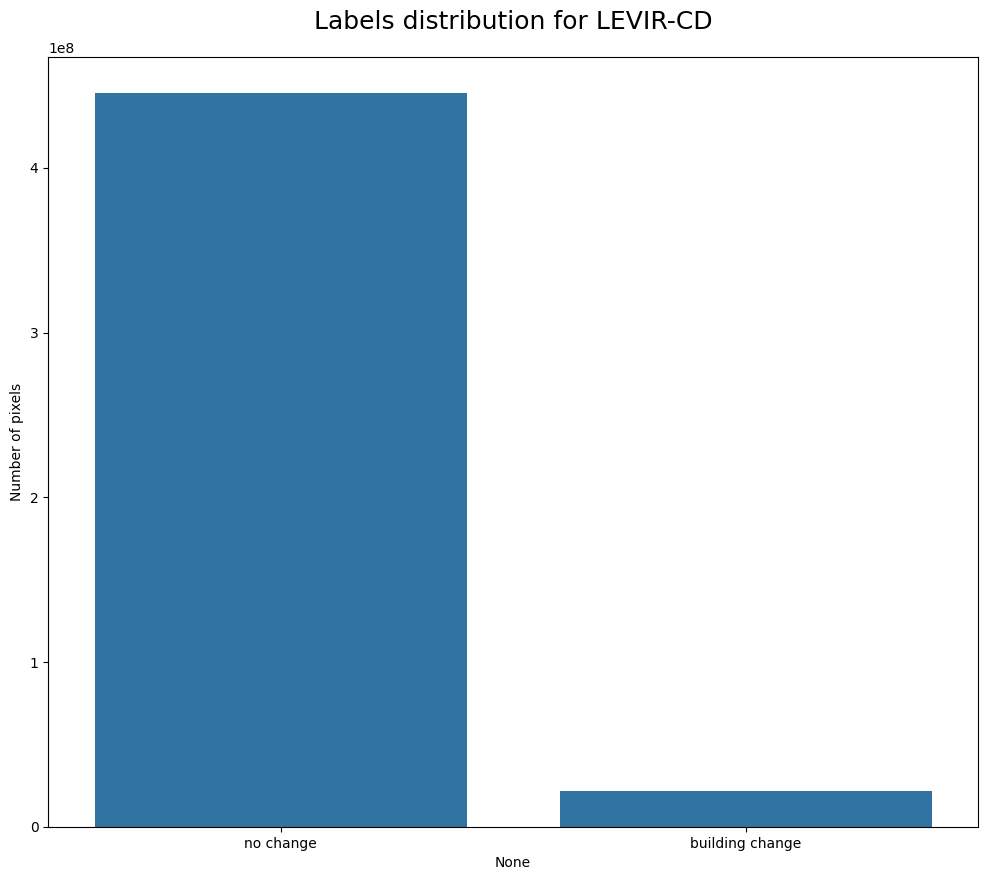

In [8]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/levir_cd/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = LEVIRCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/levir_cd/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = LEVIRCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(445, 64)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/levir_cd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 07:48:27,609 INFO Starting training.
training: 100%|██████████| 28/28 [03:34<00:00,  7.65s/it]
2026-01-29 07:52:01,972 INFO epoch: 1, loss:  0.28459
testing on train set: 100%|██████████| 28/28 [03:34<00:00,  7.66s/it]
2026-01-29 07:55:37,589 INFO Accuracy:0.8980054362436359, Accuracy per Class:[0.93169086 0.86432001], Precision Micro:0.8373292326080763, Precision Macro:0.47886450779155165, Precision Weighted:0.9076314984683077, Precision per Class:[0.93169086 0.02603816], Recall Micro:0.976598429551226, Recall Macro:0.559554055949337, Recall Weighted:0.9765984295512259, Recall per Class:[1.         0.11910811], F1_score Micro:0.9016174466504885, F1_score Macro:0.503685927453332, F1_score Weighted:0.9401465697447615, F1_score per Class:[0.96463764 0.04273421], IOU:0.8208592205885028, IOU mean:0.47676224308423126, IOU per Class:[0.93169086 0.02183363]
training: 100%|██████████| 28/28 [03:36<00:00,  7.72s/it]
2026-01-29 07:59:13,824 INFO epoch: 2, loss:  0.25270
testing on tra

## Predictions

2026-01-29 13:57:08,229 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/levir_cd/checkpoint.pth.tar
2026-01-29 13:57:08,723 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/levir_cd/checkpoint.pth.tar at epoch 51


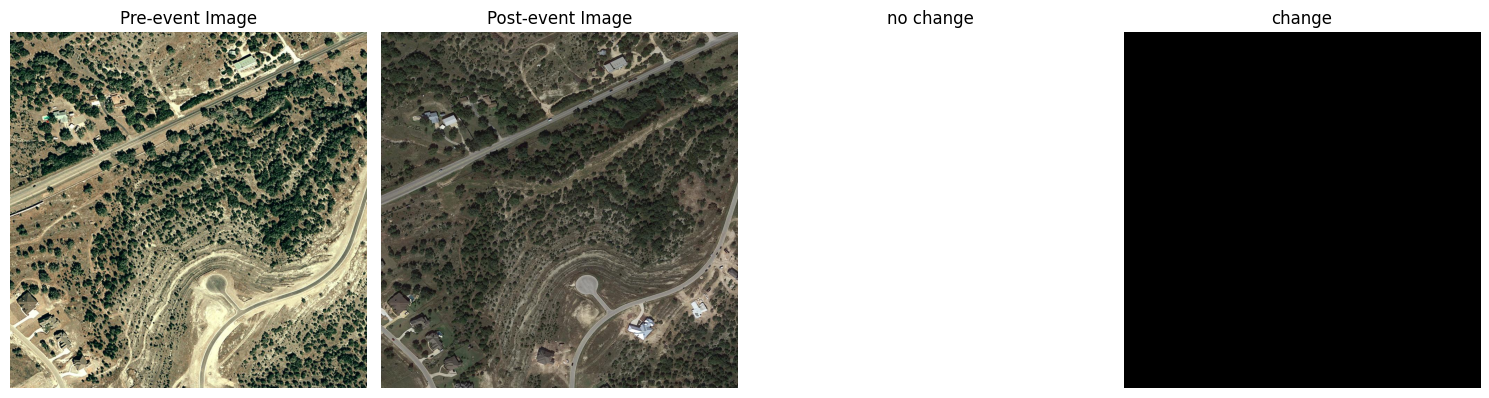

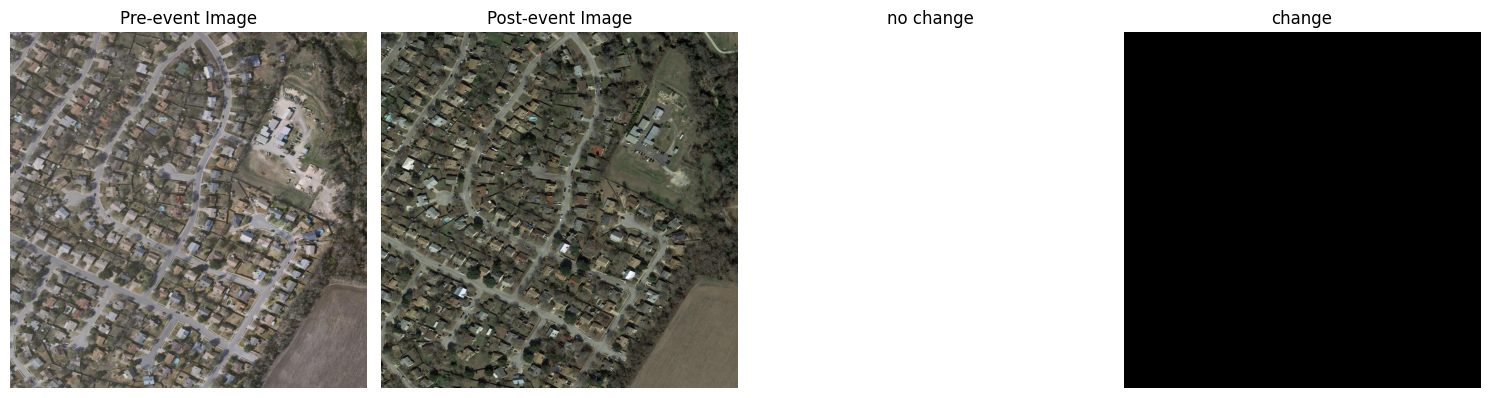

In [ ]:
model_path = "./data/experiments/levir_cd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/levir_cd/test/A/test_3.png")
image2 = image_loader("./data/levir_cd/test/B/test_3.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/levir_cd/test/A/test_62.png")
image2 = image_loader("./data/levir_cd/test/B/test_62.png")
fig = model.predict_masks(image1, image2, labels, transform)